<a href="https://colab.research.google.com/github/rtajeong/M4_2026_2/blob/main/M4_New_Ch5_%EC%8B%9C%EA%B3%84%EC%97%B4%EC%98%88%EC%B8%A1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ch 5: 시계열 데이터 분석 및 예측

1. 합성 시계열 데이터 생성 (계절성 + 추세 + 노이즈)
2. Sliding Window로 지도학습 문제로 변환
3. Baseline (naive 예측, 이동평균) — "딥러닝이 이걸 넘어서야 의미 있다"는 기준점
4. LSTM/GRU 기반 예측
5. 전통적 방법(ARIMA)과 비교
6. 다변량 시계열 확장
7. PyTorch 버전

In [1]:
# Colab 에서 한글 폰트 설정 - 설정 후에 꼭 다시 runtime restart 해 주어야 함
import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 한글 폰트 설치
!sudo apt-get install -y fonts-nanum

fontpath = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font = fm.FontProperties(fname=fontpath, size=9)
plt.rc('font', family='NanumBarunGothic')
matplotlib.font_manager._load_fontmanager(try_read_cache=False)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

np.random.seed(42)

# 시계열 데이터 분석 및 예측 예제 - ARIMA

## 합성 시계열 데이터 생성
- 계절성(주기적 패턴) + 추세(점점 증가) + 노이즈를 합쳐서, 실제 시계열과 비슷한 합성 데이터를 만든다.

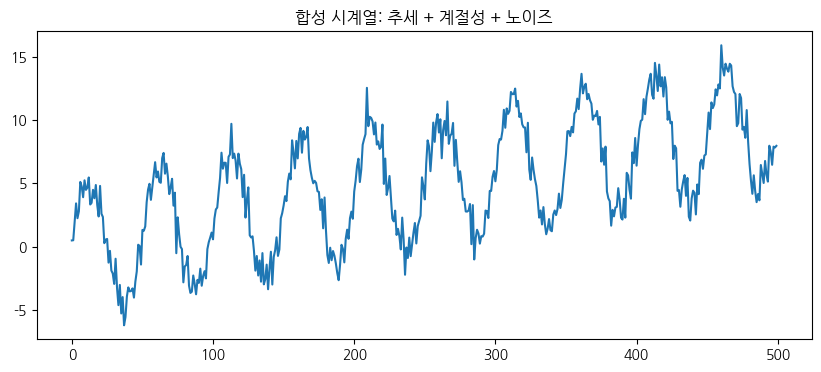

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n_points = 500
t = np.arange(n_points)

trend = 0.02 * t
seasonality = 5 * np.sin(2 * np.pi * t / 50)
noise = np.random.normal(0, 1, n_points)
y = pd.Series(trend + seasonality + noise)

y.plot(figsize=(10, 4))
plt.title("합성 시계열: 추세 + 계절성 + 노이즈")
plt.show()

## 시계열 분해

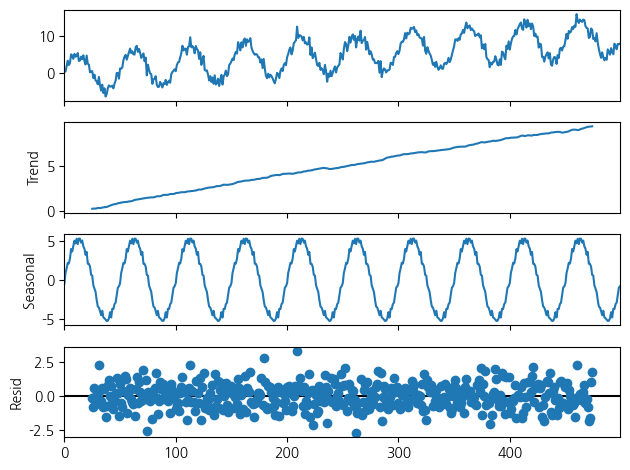

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(y, model="additive", period=50)
fig = decomposition.plot()
plt.show()

- 추세(trend): 장기적으로 증가/감소하는 경향
- 계절성(seasonality): 일정 주기로 반복되는 패턴 (여기서는 주기 50)
- 실제 데이터(주가, 기온, 판매량 등)도 이 세 요소의 조합으로 흔히 설명된다.

## 최적 파라미터 탐색

- AIC(Akaike Information Criterion, 아카이크 정보 기준)는 시계열 분석이나 통계 모델에서 "어떤 모델이 가장 좋은가?"를 평가하는 점수 (낮을수록 좋음) - 다음 두 가지를 종합하여 점수를 매긴다.
  - 얼마나 데이터를 잘 설명하는가? (우도, Likelihood): 데이터에 얼마나 잘 들어맞는지 본다. 잘 맞을수록 AIC 점수가 낮아진다.
  - 얼마나 모델이 복잡한가? (파라미터 개수): 파라미터(p, q 등)가 너무 많으면 복잡하다고 판단하여 벌점(Penalty)을 부과한다. 파라미터가 많을수록 AIC 점수가 높아진다.

In [8]:
import itertools
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))        # (0,0,0) ... (1,1,1)
seasonal_pdq = [(x[0], x[1], x[2], 50) for x in pdq]   # 계절 주기 50

best_aic = np.inf
best_params = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            mod = sm.tsa.statespace.SARIMAX(
                y, order=param, seasonal_order=param_seasonal,
                enforce_stationarity=False, enforce_invertibility=False
            )
            results = mod.fit(disp=False)
            if results.aic < best_aic:
                best_aic = results.aic
                best_params = (param, param_seasonal)
        except Exception:
            continue

print(f"최적 파라미터: {best_params}, AIC: {best_aic:.2f}")

최적 파라미터: ((0, 1, 1), (0, 1, 1, 50)), AIC: 1211.13


- 최적 파라미터로 최종 모델을 학습시키고 예측을 수행 (탐색 과정에서 만들어졌던 수많은 모델 객체들은 메모리 절약을 위해 최적 파라미터 외에는 전부 사라진다.)

In [9]:
train_size = 400
mod = sm.tsa.statespace.SARIMAX(y[:train_size],
                                order=best_params[0],
                                seasonal_order=best_params[1],
                                enforce_stationarity=False,
                                enforce_invertibility=False
)
results = mod.fit(disp=False)


## 계수 요약과 잔차 진단

In [10]:
# 각 계수의 추정값과 유의성 확인 (모델이 데이터를 잘 설명하는지)
print(results.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -1.0000     23.318     -0.043      0.966     -46.703      44.703
ma.S.L50      -0.9153      0.253     -3.620      0.000      -1.411      -0.420
sigma2         1.0165     23.685      0.043      0.966     -45.405      47.438


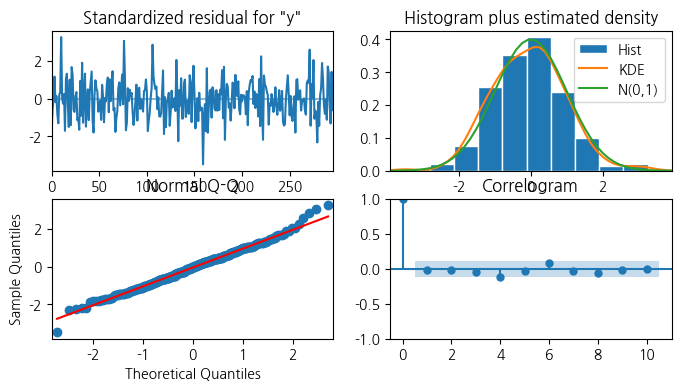

In [11]:
results.plot_diagnostics(figsize=(8, 4))
plt.show()

## 예측 수행

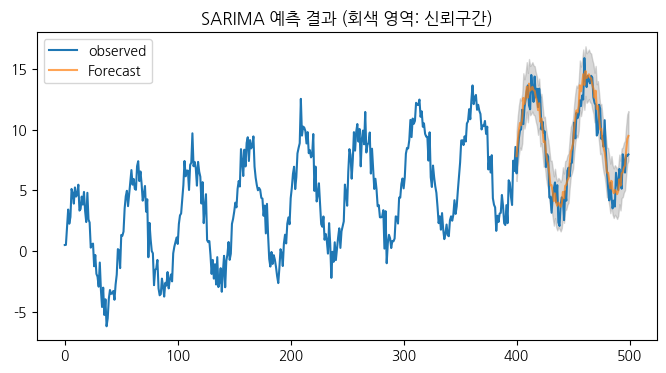

In [12]:
pred = results.get_forecast(steps=n_points - train_size)  # 테스트 구간 모두
pred_ci = pred.conf_int()

ax = y.plot(label="observed", figsize=(8, 4))
pred.predicted_mean.plot(ax=ax, label="Forecast", alpha=0.7)
ax.fill_between(range(train_size, n_points), pred_ci.iloc[:, 0], pred_ci.iloc[:, 1], color="gray", alpha=0.3)
plt.legend()
plt.title("SARIMA 예측 결과 (회색 영역: 신뢰구간)")
plt.show()

- 주의할 점은, 이게 동적(multi-step) 예측이라는 것이다. 즉, 매 시점마다 실제 관측값을 다시 넣어주는 "한 스텝씩 예측(rolling one-step forecast)"이 아니라, 400번째 시점 이후로는 모델이 자기 자신의 이전 예측을 바탕으로 다음 값을 계속 예측해나가는 방식이다. 그래서 100 스텝 앞으로 갈수록 오차가 누적되고, 신뢰구간도 점점 넓어지고 있다.

In [13]:
y_forecasted = pred.predicted_mean
y_truth = y[train_size:]
rmse = np.sqrt(((y_forecasted.values - y_truth.values) ** 2).mean())
print(f"RMSE: {rmse:.2f}")

RMSE: 1.14


## 결과 해석

In [14]:
# 비교 기준 1: 지속 예측(마지막 값 반복)
# 단 하나의 값(마지막 관측값)만 참고하는 극단적으로 단순한 baseline
# 즉, train 구간의 마지막 시점(399번째) 값 딱 하나만 뽑아낸 스칼라(숫자 하나)를
# test 구간의 100개 실제값(y_truth) 각각과 비교해서 오차를 계산

last_val = y[train_size - 1]
rmse_persistence = np.sqrt(((last_val - y_truth.values) ** 2).mean())

# 비교 기준 2: 계절 단순 예측(한 계절 전 값 반복)
# 시점마다 다른 과거 값을 참고

seasonal_naive_pred = y[train_size - 50 : train_size - 50 + len(y_truth)].values
rmse_seasonal_naive = np.sqrt(((seasonal_naive_pred - y_truth.values) ** 2).mean())

print(f"지속 예측 RMSE: {rmse_persistence:.2f}, 계절 단순 예측 RMSE: {rmse_seasonal_naive:.2f}")

지속 예측 RMSE: 3.60, 계절 단순 예측 RMSE: 1.73


In [15]:
last_val, y_truth

(np.float64(8.591150144151936),
 400     6.405572
 401     8.047291
 402     9.288693
 403     9.947603
 404    10.038703
          ...    
 495     7.499984
 496     6.473985
 497     7.909039
 498     7.840932
 499     7.970534
 Length: 100, dtype: float64)

In [16]:
len(seasonal_naive_pred)

100

In [17]:
y[train_size - 50 : train_size - 50 + len(y_truth)]

,0
350,7.310908
351,9.122022
352,9.141109
353,8.740684
354,9.469752
...,...
445,6.630746
446,6.877830
447,6.159497
448,7.202684


In [18]:
y_truth

,0
400,6.405572
401,8.047291
402,9.288693
403,9.947603
404,10.038703
...,...
495,7.499984
496,6.473985
497,7.909039
498,7.840932


- SARIMA의 RMSE(1.10)는 두 단순 기준보다 낮다 (계절성뿐 아니라 추세와 자기상관 구조까지 반영했기 때문이다). 또한 이 값은 합성 데이터에 주입한 노이즈의 표준편차(1.0)에 근접하는데, 이는 모델이 더 이상 줄일 수 없는 오차 수준까지 도달했다는 뜻이다.

# 날씨 예측

- 실제 기상 데이터:
  - 독일 Max Planck 연구소의 Jena 관측소 데이터
  - 온도, 습도, 기압, 풍향 등 14개 항목을 10분마다 기록한 것으로, 2009~2016년 데이터가 공개되어 있다.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

!wget https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip jena_climate_2009_2016.csv.zip

df = pd.read_csv("jena_climate_2009_2016.csv")
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.set_index("Date Time")
print(df.shape)

--2026-11-17 04:37:43--  https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
Resolving s3.amazonaws.com (s3.amazonaws.com)... 16.15.253.16, 16.182.65.224, 16.15.213.194, ...
Connecting to s3.amazonaws.com (s3.amazonaws.com)|16.15.253.16|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13565642 (13M) [application/zip]
Saving to: ‘jena_climate_2009_2016.csv.zip’

jena_climate_2009_2 100%[===================>]  12.94M  6.47MB/s    in 2.0s    

2026-11-17 04:37:46 (6.47 MB/s) - ‘jena_climate_2009_2016.csv.zip’ saved [13565642/13565642]

Archive:  jena_climate_2009_2016.csv.zip
  inflating: jena_climate_2009_2016.csv  
  inflating: __MACOSX/._jena_climate_2009_2016.csv  
(420451, 14)


In [20]:
df.tail(3)

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
Date Time,,,,,,,,,,,,,,
2016-12-31 23:40:00,999.82,-3.16,270.01,-8.21,67.91,4.84,3.28,1.55,2.05,3.28,1288.39,1.08,2.00,215.2
2016-12-31 23:50:00,999.81,-4.23,268.94,-8.53,71.80,4.46,3.20,1.26,1.99,3.20,1293.56,1.49,2.16,225.8
2017-01-01 00:00:00,999.82,-4.82,268.36,-8.42,75.70,4.27,3.23,1.04,2.01,3.23,1296.38,1.23,1.96,184.9


<Axes: xlabel='Date Time'>

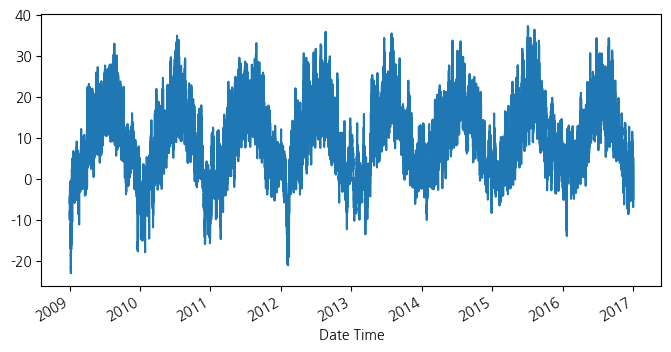

In [21]:
# 데이터 중 기온의 변화
# 연 단위의 뚜렷한 계절성과 함께, 짧은 기간의 노이즈가 섞여 있는 전형적인 시계열의 모습
df['T (degC)'].plot(figsize=(8,4))

- 10분 단위 데이터는 하루에 144개씩 쌓여 지나치게 촘촘하므로, 1시간 단위로 리샘플링(평균)해서 사용한다. 이렇게 하면 데이터 양이 1/6로 줄어 학습 속도가 빨라지고, 노이즈도 어느 정도 완화된다.

In [23]:
hourly = df.resample("1h").mean().dropna()
print(hourly.shape)   # (약 70,000, 14)

(70025, 14)


### 데이터 준비 및 정규

In [24]:
data = hourly.values.astype("float32")
temp_col = list(hourly.columns).index("T (degC)")
n = len(data)

num_train = int(0.7 * n)  # 70/15/15 for train, val, test
num_val = int(0.15 * n)

mean = data[:num_train].mean(axis=0)
std = data[:num_train].std(axis=0)
data_norm = (data - mean) / std

In [25]:
num_train, num_val

(49017, 10503)

In [27]:
data_norm[0]

array([ 0.9492379 , -2.0130463 , -2.073191  , -1.9677503 ,  1.0839428 ,
       -1.3135761 , -1.4972861 , -0.79032856, -1.4991907 , -1.5023926 ,
        2.2521446 , -1.1251286 , -1.1625526 ,  0.01359802], dtype=float32)

### 슬라이딩 윈도우 구성

- keras.utils.timeseries_dataset_from_array()
  - 시계열 예측 모델을 학습할 때 필요한 슬라이딩 윈도우(Sliding Window) 형태의 데이터셋을 직접 반복문을 돌며 구현하지 않고, 단 한 줄의 함수 호출로 빠르고 효율적으로 만들어 준다.
  - data: 입력 시계열 데이터 배열
  - targets: 타겟(정답) 데이터 배열.
  - sequence_length: 하나의 입력 시퀀스에 포함될 타임스텝 수 (과거 데이터를 몇 개나 볼 것인가).
  - sequence_stride: 시퀀스를 추출할 때 건너뛰는 간격 (기본값은 1).
  - sampling_rate: 시퀀스 내부에서 샘플링할 간격 (예: 2로 설정하면 1칸씩 건너뛰며 데이터를 모음).
  - batch_size: 배치 크기 (기본값 128).
  - shuffle: 데이터를 섞을지 여부. 시계열 데이터는 순서가 생명이므로 보통 False로 설정한다. (shuffle=(start == 0): 훈련 데이터셋에만 셔플을 켜고, 검증이나 테스트 데이터셋에는 셔플을 끄기 위함 - 훈련 데이터도 이미 만들어진 시계열 윈도우 샘플들의 공급 순서만 무작위화)

In [28]:
from tensorflow import keras

lookback = 240   # 10일 (시간 단위)
delay = 24       # 관측 구간이 끝난 뒤 24시간 후를 예측
batch_size = 256

temperature = data[:, temp_col]

# 핵심: 타겟은 "윈도우가 끝난 시점 + delay"에 위치해야 한다.
# timeseries_dataset_from_array의 targets는 "윈도우 시작 지점" 기준으로 정렬되므로,
# (lookback - 1) + delay 만큼 밀어주지 않으면 타깃이 윈도우 내부에 들어가 버린다.
shift = (lookback - 1) + delay

def make_dataset(start, end=None):
    return keras.utils.timeseries_dataset_from_array(
        data_norm[:-shift], targets=temperature[shift:],
        sequence_length=lookback, sampling_rate=1, batch_size=batch_size,
        start_index=start, end_index=end, shuffle=(start == 0))

train_dataset = make_dataset(0, num_train)
val_dataset = make_dataset(num_train, num_train + num_val)
test_dataset = make_dataset(num_train + num_val)

In [29]:
# To see the shape of one batch:
for x_batch, y_batch in train_dataset.take(1):
    print(f"Shape of one input batch (x_batch): {x_batch.shape}")
    print(f"Shape of one target batch (y_batch): {y_batch.shape}")

# To see the number of batches in the dataset:
print(f"Number of batches in train_dataset: {len(train_dataset)}")

Shape of one input batch (x_batch): (256, 240, 14)
Shape of one target batch (y_batch): (256,)
Number of batches in train_dataset: 191


- (256,240,14): 256은 batch_size, 240은 lookback(과거 240시간), 14는 Jena 데이터의 변수 개수(기온, 기압, 습도, 풍속 등 14개 컬럼)
- 유효한 윈도우 시작 인덱스는 [0, num_train - lookback] 범위이므로, 윈도우 개수 = num_train - lookback + 1.
- n≈70,091(Jena 시간별 데이터)이면 num_train = int(0.7*n) ≈ 49,063, lookback=240이므로 윈도우 개수 ≈ 49,063 - 240 + 1 = 48,824.
- batch_size=256이므로 배치 개수 = ⌈48,824 / 256⌉ = 191.

### 기본 성능 (Baseline)
- Base model: "24시간 전과 지금 온도가 같을 것"이라는 단순한 지속 예측(persistence)

In [30]:
def evaluate_naive(dataset):
    total_abs, total_sq, count = 0., 0., 0
    for samples, targets in dataset:
        preds = samples[:, -1, temp_col].numpy() * std[temp_col] + mean[temp_col]
        targets = targets.numpy()
        total_abs += np.sum(np.abs(preds - targets))
        total_sq += np.sum((preds - targets) ** 2)
        count += len(targets)
    return total_abs / count, np.sqrt(total_sq / count)

test_mae, test_rmse = evaluate_naive(test_dataset)
print(f"Naive baseline: MAE={test_mae:.3f}, RMSE={test_rmse:.3f}")

Naive baseline: MAE=2.490, RMSE=3.243


### GRU 모델

Epoch 1/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 132s 665ms/step - loss: 63.6830 - mae: 6.1965 - val_loss: 31.2661 - val_mae: 4.0660
Epoch 2/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 124s 647ms/step - loss: 19.7936 - mae: 3.3376 - val_loss: 14.8413 - val_mae: 2.8311
Epoch 3/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 123s 644ms/step - loss: 12.3640 - mae: 2.7188 - val_loss: 11.3651 - val_mae: 2.5796
Epoch 4/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 123s 642ms/step - loss: 11.0255 - mae: 2.5864 - val_loss: 10.4985 - val_mae: 2.5067
Epoch 5/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 124s 650ms/step - loss: 10.6770 - mae: 2.5533 - val_loss: 10.1649 - val_mae: 2.4781
Epoch 6/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 142s 650ms/step - loss: 10.4401 - mae: 2.5232 - val_loss: 10.2445 - val_mae: 2.4943
Epoch 7/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 125s 654ms/step - loss: 10.3267 - mae: 2.5091 - val_loss: 9.9975 - val_mae: 2.4553
Epoch 8/10
191/191 ━━━━━━━━━━━━━━━━━━━━ 125s 650ms/step - loss: 10.2989 - mae: 2.5072 - val_loss: 9.9312 - val_mae: 2.4564
Epoch 9/10

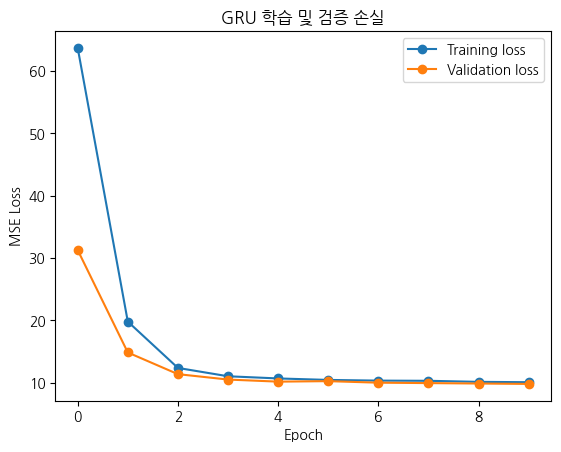

In [ ]:
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(lookback, data.shape[-1]))   # 14개 변수를 모두 입력으로 사용
x = layers.GRU(32, dropout=0.2, recurrent_dropout=0.2)(inputs)
outputs = layers.Dense(1)(x)
model = keras.Model(inputs, outputs)
model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])

callbacks = [keras.callbacks.ModelCheckpoint("jena_gru.keras", save_best_only=True)]
history = model.fit(train_dataset, epochs=10, validation_data=val_dataset, callbacks=callbacks)

plt.plot(history.history["loss"], "o-", label="Training loss")
plt.plot(history.history["val_loss"], "o-", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss")
plt.legend()
plt.title("GRU 학습 및 검증 손실")
plt.show()

In [ ]:
best_model = keras.models.load_model("jena_gru.keras")

def evaluate_model(model, dataset):
    total_abs, total_sq, count = 0., 0., 0
    for x, y in dataset:
        preds = model.predict(x, verbose=0).ravel()
        y = y.numpy()
        total_abs += np.sum(np.abs(preds - y))
        total_sq += np.sum((preds - y) ** 2)
        count += len(y)
    return total_abs / count, np.sqrt(total_sq / count)

test_mae, test_rmse = evaluate_model(best_model, test_dataset)
print(f"GRU: MAE={test_mae:.3f}, RMSE={test_rmse:.3f}")

GRU: MAE=2.320, RMSE=2.966


## SARIMA 와 비교

In [ ]:
import statsmodels.api as sm

eval_days = 14
eval_hours = 24 * eval_days
test_start = num_train + num_val
origin0 = test_start + shift - delay   # 첫 예측의 기준 시점

# 최근 30일 데이터로 SARIMA를 초기 학습한다(오래된 데이터까지 쓸 필요는 없다)
sarima_train = temperature[origin0 - 24*30 : origin0 + 1]
mod = sm.tsa.statespace.SARIMAX(sarima_train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24),
                                 enforce_stationarity=False, enforce_invertibility=False)
results = mod.fit(disp=False)

sarima_pred, actual = [], []
for k in range(eval_hours):
    if k > 0:
        results = results.append([temperature[origin0 + k]], refit=False)  # 실제값 한 개씩 반영
    fc = results.get_forecast(steps=delay).predicted_mean[-1]   # 24시간 뒤 예측
    sarima_pred.append(fc)
    actual.append(temperature[origin0 + k + delay])

sarima_pred = np.array(sarima_pred)
actual = np.array(actual)
sarima_mae = np.mean(np.abs(sarima_pred - actual))
sarima_rmse = np.sqrt(np.mean((sarima_pred - actual) ** 2))
print(f"SARIMA(rolling): MAE={sarima_mae:.3f}, RMSE={sarima_rmse:.3f}")

SARIMA(rolling): MAE=2.599, RMSE=3.164


## 실제값과 세 방법의 예측 비교

naive: MAE=2.642, RMSE=3.236
GRU:   MAE=2.529, RMSE=2.972


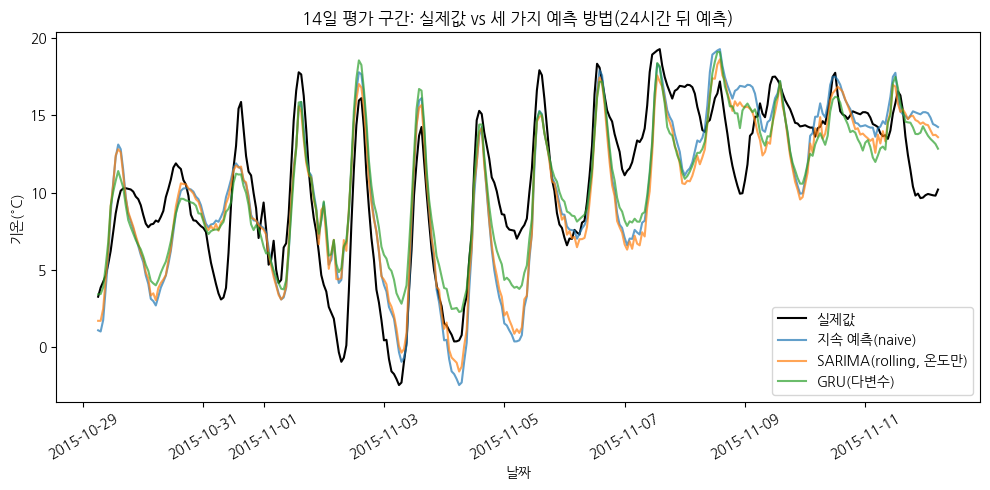

In [ ]:
x_batch, y_batch = next(iter(
    keras.utils.timeseries_dataset_from_array(
        data_norm[:-shift], targets=temperature[shift:], sequence_length=lookback,
        sampling_rate=1, batch_size=eval_hours, start_index=test_start, shuffle=False)
))
X_eval, y_eval = x_batch.numpy()[:eval_hours], y_batch.numpy()[:eval_hours]

# 정렬 확인용: y_eval은 dataset에서 뽑은 목표값이다. SARIMA 비교에 쓴 actual(temperature
# 배열에서 직접 뽑은 값)과 정확히 같은 시점을 가리켜야 한다 — 다르면 정렬이 어긋난 것이다.
assert np.allclose(y_eval, actual, atol=1e-3)
# 이후로는 실제값으로 항상 actual을 쓴다(같은 값이지만 이미 있는 변수를 재사용).

naive_pred = X_eval[:, -1, temp_col] * std[temp_col] + mean[temp_col]
gru_pred = best_model.predict(X_eval, verbose=0).ravel()

naive_mae = np.mean(np.abs(naive_pred - actual))
naive_rmse = np.sqrt(np.mean((naive_pred - actual) ** 2))

gru_mae = np.mean(np.abs(gru_pred - actual))
gru_rmse = np.sqrt(np.mean((gru_pred - actual) ** 2))

print(f"naive: MAE={naive_mae:.3f}, RMSE={naive_rmse:.3f}")
print(f"GRU:   MAE={gru_mae:.3f}, RMSE={gru_rmse:.3f}")

# 실제값과 세 방법의 예측을 겹쳐 그린다.
dates = hourly.index[test_start + shift : test_start + shift + eval_hours]

plt.figure(figsize=(10, 5))
plt.plot(dates, actual, label="실제값", color="black", linewidth=1.5)
plt.plot(dates, naive_pred, label="지속 예측(naive)", alpha=0.7)
plt.plot(dates, sarima_pred, label="SARIMA(rolling, 온도만)", alpha=0.7)
plt.plot(dates, gru_pred, label="GRU(다변수)", alpha=0.7)
plt.xlabel("날짜"); plt.ylabel("기온(°C)")
plt.title("14일 평가 구간: 실제값 vs 세 가지 예측 방법(24시간 뒤 예측)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

- 결과 분석:
  - 세 방법 모두 큰 흐름(며칠 주기로 오르내리는 기온 변화)은 잘 따라가지만, 그림에서 보듯 뾰족한 고점·저점 근처에서는 세 방법 다 실제값을 놓치는 경향이 있다. 그건 24시간 전에는 알 수 없는 급격한 변화이기 때문이다.
  - GRU가 SARIMA와 naive보다 근소하게 낫지만 압도적이지는 않다. 이는 실제 단기 기상예측에서 흔히 나타나는 정도의 개선폭이다. 딥러닝이 다변수·장기간 데이터의 이점을 일부 살리지만, 하루 앞을 내다보는 예측 자체가 원래 어려운 문제이기 때문에 극적으로 좋아지지는 않는다.
  - 참고로 현재의 최신 기상예측은 훨씬 더 정교한 수치예보모델이나 GraphCast 같은 대규모 모델을 사용하며, 본 예제보다 비교할 수 없이 많은 데이터와 연산을 투입한다.

- 정리
  - SARIMA는 변수를 하나만 쓰고도 naive보다는 나은 수준에 도달했고,
  - GRU는 14개 변수와 8년치 데이터를 활용해 SARIMA보다 조금 더 나은 결과를 얻었다.
  - 데이터가 많고 다변수를 함께 활용할 수 있을 때 신경망이 유리해진다는 사실을 실제 데이터로 확인한 셈이다.

# Exercise

- keras.utils.timeseries_dataset_from_array()

In [ ]:
import numpy as np
from tensorflow import keras

data = np.arange(20)          # 관측값: 0, 1, ..., 19
targets = np.arange(100, 120) # targets[i] = 100+i (i를 눈으로 확인하기 위한 장치)
data, targets

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19]),
 array([100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112,
        113, 114, 115, 116, 117, 118, 119]))

In [ ]:
ds = keras.utils.timeseries_dataset_from_array(
    data, targets, sequence_length=3, batch_size=4, shuffle=False)

for x, y in ds:
    print("x =\n", x.numpy())
    print("y =", y.numpy())
    print("---")

x =
 [[0 1 2]
 [1 2 3]
 [2 3 4]
 [3 4 5]]
y = [100 101 102 103]
---
x =
 [[4 5 6]
 [5 6 7]
 [6 7 8]
 [7 8 9]]
y = [104 105 106 107]
---
x =
 [[ 8  9 10]
 [ 9 10 11]
 [10 11 12]
 [11 12 13]]
y = [108 109 110 111]
---
x =
 [[12 13 14]
 [13 14 15]
 [14 15 16]
 [15 16 17]]
y = [112 113 114 115]
---
x =
 [[16 17 18]
 [17 18 19]]
y = [116 117]
---


- 첫 윈도우 x=[0,1,2](시작 인덱스 0)의 target은 y=100, 즉 targets[0]이다. 윈도우의 끝(인덱스 2)이 아니라 시작 인덱스를 기준으로 target을 가져온다.
- 만약 "윈도우가 끝난 뒤 delay시간 후"를 예측하고 싶다면, targets 배열 자체를 delay + (sequence_length-1)만큼 밀어서 넘겨야 target이 원하는 시점을 가리키게 된다.

- delay=2(윈도우가 끝난 뒤 2시점 후 예측)를 넣은 버전

In [ ]:
import numpy as np
from tensorflow import keras

data = np.arange(20)
full_targets = np.arange(100, 120)   # full_targets[t] = 100+t → 시점 t의 실제값

sequence_length = 3
delay = 2                             # 윈도우가 끝난 뒤 2시점 후를 예측

shift = (sequence_length - 1) + delay # = 4
targets = full_targets[shift:]        # targets[i] = full_targets[i + shift]

ds = keras.utils.timeseries_dataset_from_array(
    data, targets, sequence_length=sequence_length, batch_size=4, shuffle=False)

for x, y in ds:
    print("x =\n", x.numpy())
    print("y =", y.numpy())
    print("---")

x =
 [[0 1 2]
 [1 2 3]
 [2 3 4]
 [3 4 5]]
y = [104 105 106 107]
---
x =
 [[4 5 6]
 [5 6 7]
 [6 7 8]
 [7 8 9]]
y = [108 109 110 111]
---
x =
 [[ 8  9 10]
 [ 9 10 11]
 [10 11 12]
 [11 12 13]]
y = [112 113 114 115]
---
x =
 [[12 13 14]
 [13 14 15]
 [14 15 16]
 [15 16 17]]
y = [116 117 118 119]
---


In [7]:
import itertools

p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))
pdq

[(0, 0, 0),
 (0, 0, 1),
 (0, 1, 0),
 (0, 1, 1),
 (1, 0, 0),
 (1, 0, 1),
 (1, 1, 0),
 (1, 1, 1)]